# Validação Externa Geográfica do PreviTU V6 (`sem_gram`)

Este notebook avalia o **modelo congelado** `previtu_v6_hgb_sem_gram.joblib` (treinado exclusivamente na coorte HC-UFMG 2011–2022, sem nenhum retreinamento ou ajuste de pesos) em duas coortes externas independentes dos Estados Unidos:

1. **Taylor et al. (2018) — Yale Emergency Department (PLOS ONE):** 80.387 atendimentos de pronto-socorro (`pone.0194085.s001.csv`).
2. **Parente / Dhanda et al. (2023) — University of Kansas Primary Care (Annals of Family Medicine):** 472 consultas de atenção primária (`PrimaryCare_Deidentified.txt`).

**Saídas salvas automaticamente em:** `/content/drive/MyDrive/Todos os arquivos GPT/resultados_validacao_externa_v6/`
- `Resumo_Validacao_Externa_PreviTU_V6.xlsx` e `summary_validacao_externa_v6.csv`
- `auditoria_harmonizacao_colunas.csv` (taxa de ausentes e valores mapeados por variável)
- `fig_validacao_externa_roc_pr.png` e `fig_validacao_externa_calibracao.png` (300 dpi)


In [ ]:
# Célula 1 — Montar Google Drive e conferir versão do scikit-learn compatível com o artefato V6
import json
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

BASE_DRIVE = Path("/content/drive/MyDrive/Todos os arquivos GPT")
ART_DIR = BASE_DRIVE / "previtu_v6_artefatos"
card_path = ART_DIR / "model_card_v6_sem_gram.json"
card = json.loads(card_path.read_text(encoding="utf-8"))
expected_sk = card.get("sklearn_version", "")

import sklearn
print(f"Versão atual no Colab: scikit-learn {sklearn.__version__}")
print(f"Versão do artefato congelado (model card): scikit-learn {expected_sk}")

if expected_sk and sklearn.__version__ != expected_sk:
    print(f"ATENÇÃO: divergência de versão! Se der erro ao carregar o .joblib abaixo, rode:")
    print(f"  !pip install -q scikit-learn=={expected_sk}")
    print("e reinicie a sessão antes de rodar a Célula 2.")


Mounted at /content/drive
Versão atual no Colab: scikit-learn 1.6.1
Versão do artefato congelado (model card): scikit-learn 1.7.2
ATENÇÃO: divergência de versão! Se der erro ao carregar o .joblib abaixo, rode:
  !pip install -q scikit-learn==1.7.2
e reinicie a sessão antes de rodar a Célula 2.


In [ ]:
 !pip install -q scikit-learn==1.7.2

Modelo carregado: V6_HGB_SEM_GRAM_2026-11-24 | SHA-256: 462aded6ff5d...
Limiares congelados (HC-UFMG 2011–2022): sensibilidade_95=0.053576 | youden=0.203432

--- Carregando Taylor et al. (2018) — Yale ED ---
Taylor carregado: (80387, 14) | Colunas lidas: ['PATID', 'split', 'UCX_abnormal', 'age', 'gender', 'ua_ph', 'ua_spec_grav', 'ua_leuk', 'ua_nitrite', 'ua_blood', 'ua_glucose', 'ua_wbc', 'ua_rbc', 'ua_bacteria']
  [Taylor bruto] ua_leuk: {'negative': 44406, 'small': 24215, 'large': 6543, 'moderate': 5063, 'other': 133, 'not_reported': 27}
  [Taylor bruto] ua_nitrite: {'negative': 72556, 'positive': 7662, 'other': 150, 'not_reported': 19}
  [Taylor bruto] ua_blood: {'negative': 44585, 'small': 14065, 'large': 13330, 'moderate': 7380, 'other': 999, 'not_reported': 28}
  [Taylor bruto] ua_glucose: {'negative': 72645, 'small': 5409, 'large': 1753, 'moderate': 509, 'other': 55, 'not_reported': 16}
  [Taylor bruto] ua_wbc: {'small': 31904, 'not_reported': 21391, 'moderate': 19800, 'large':

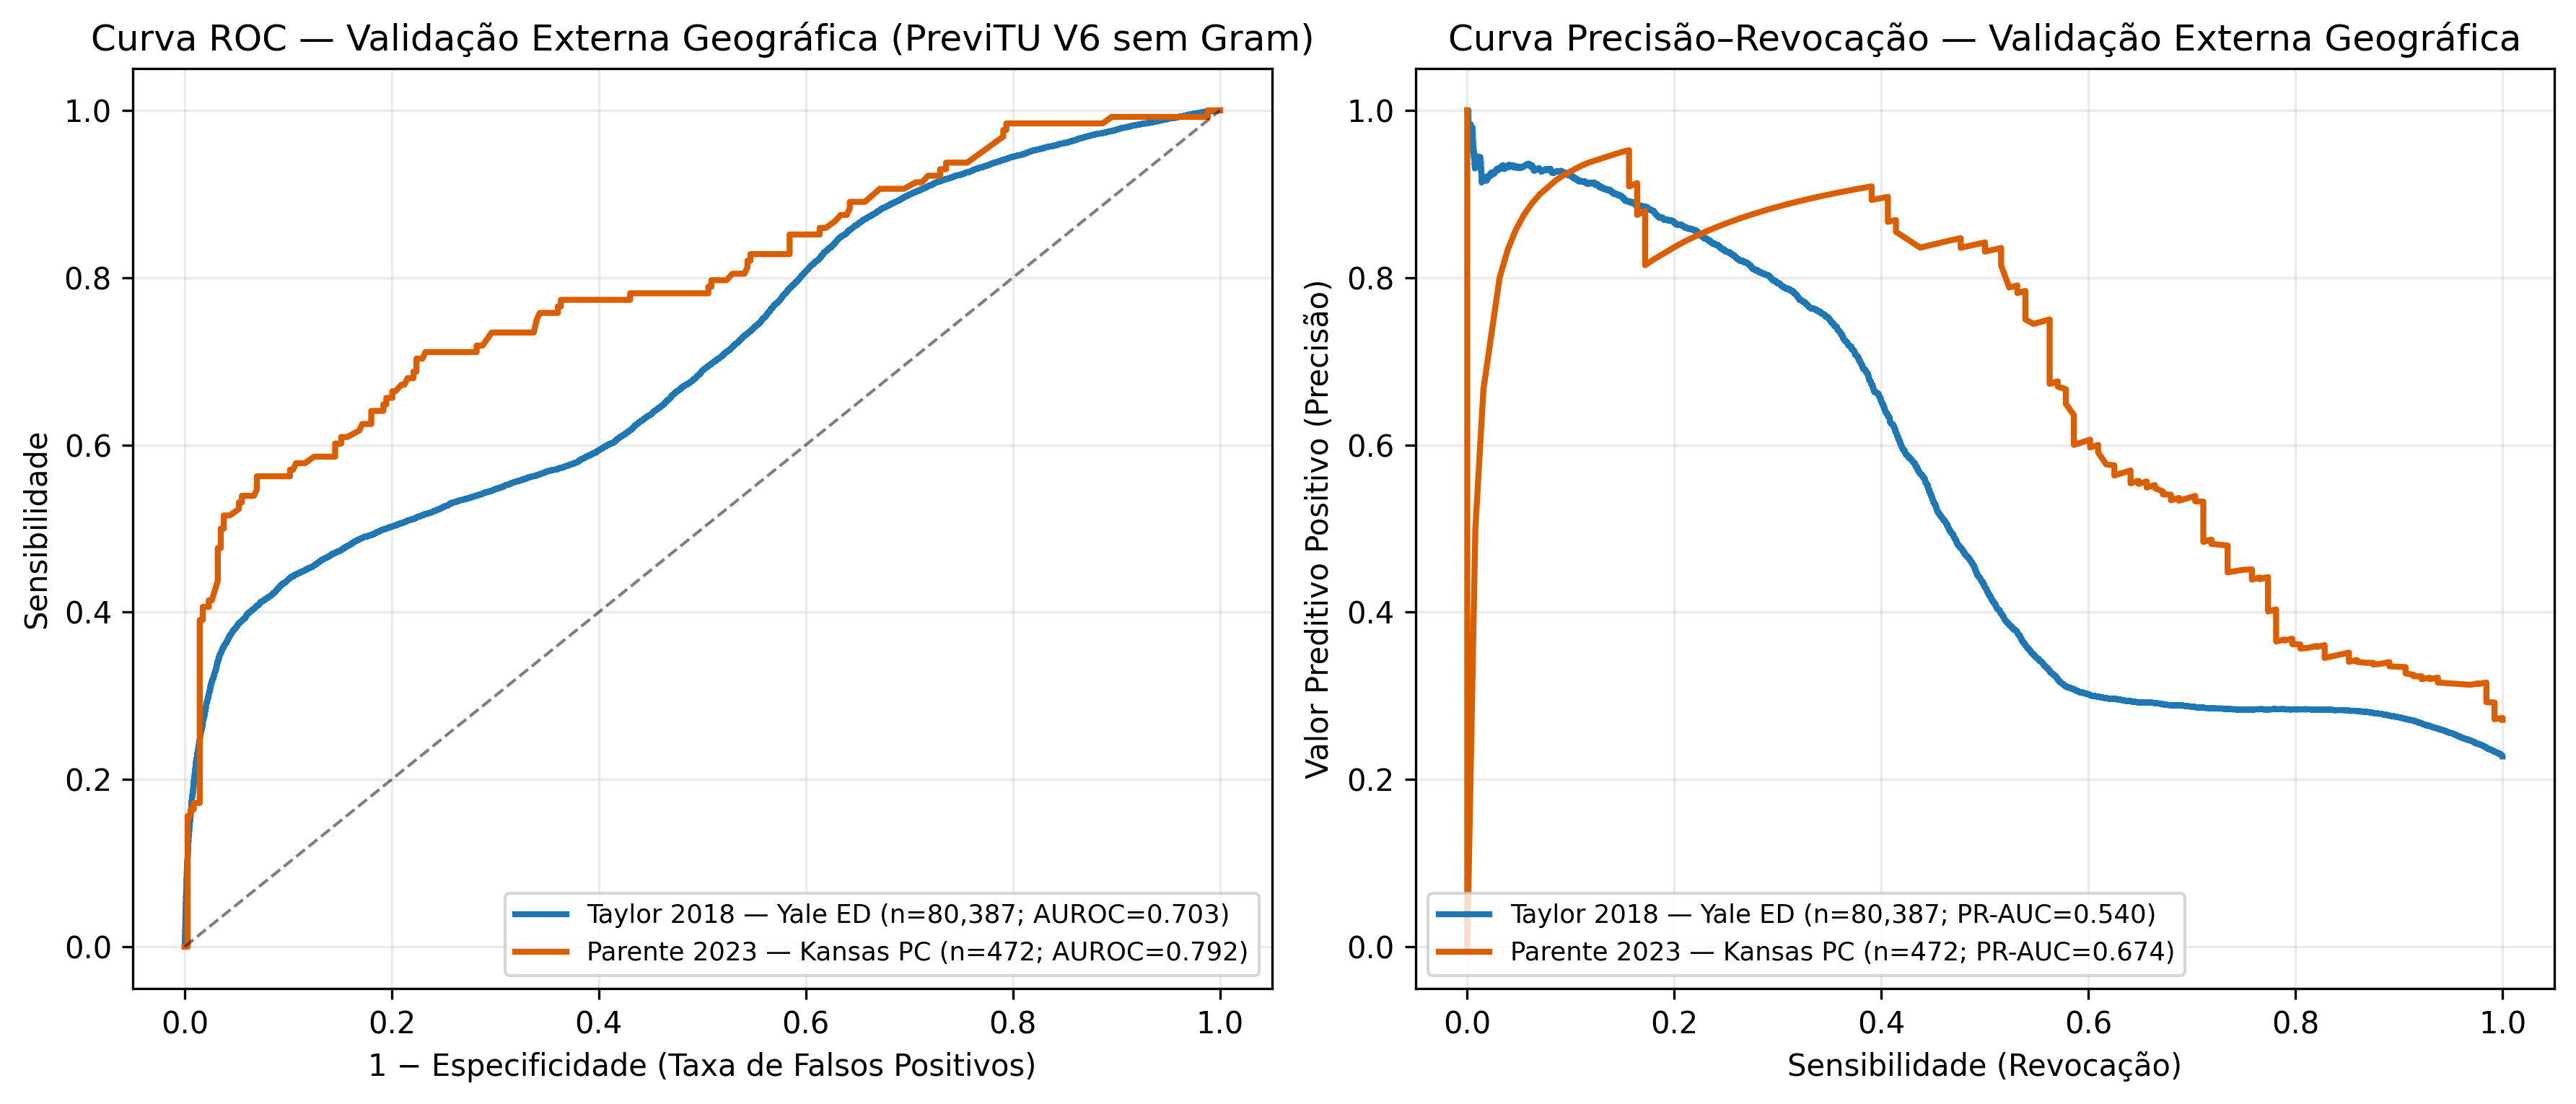

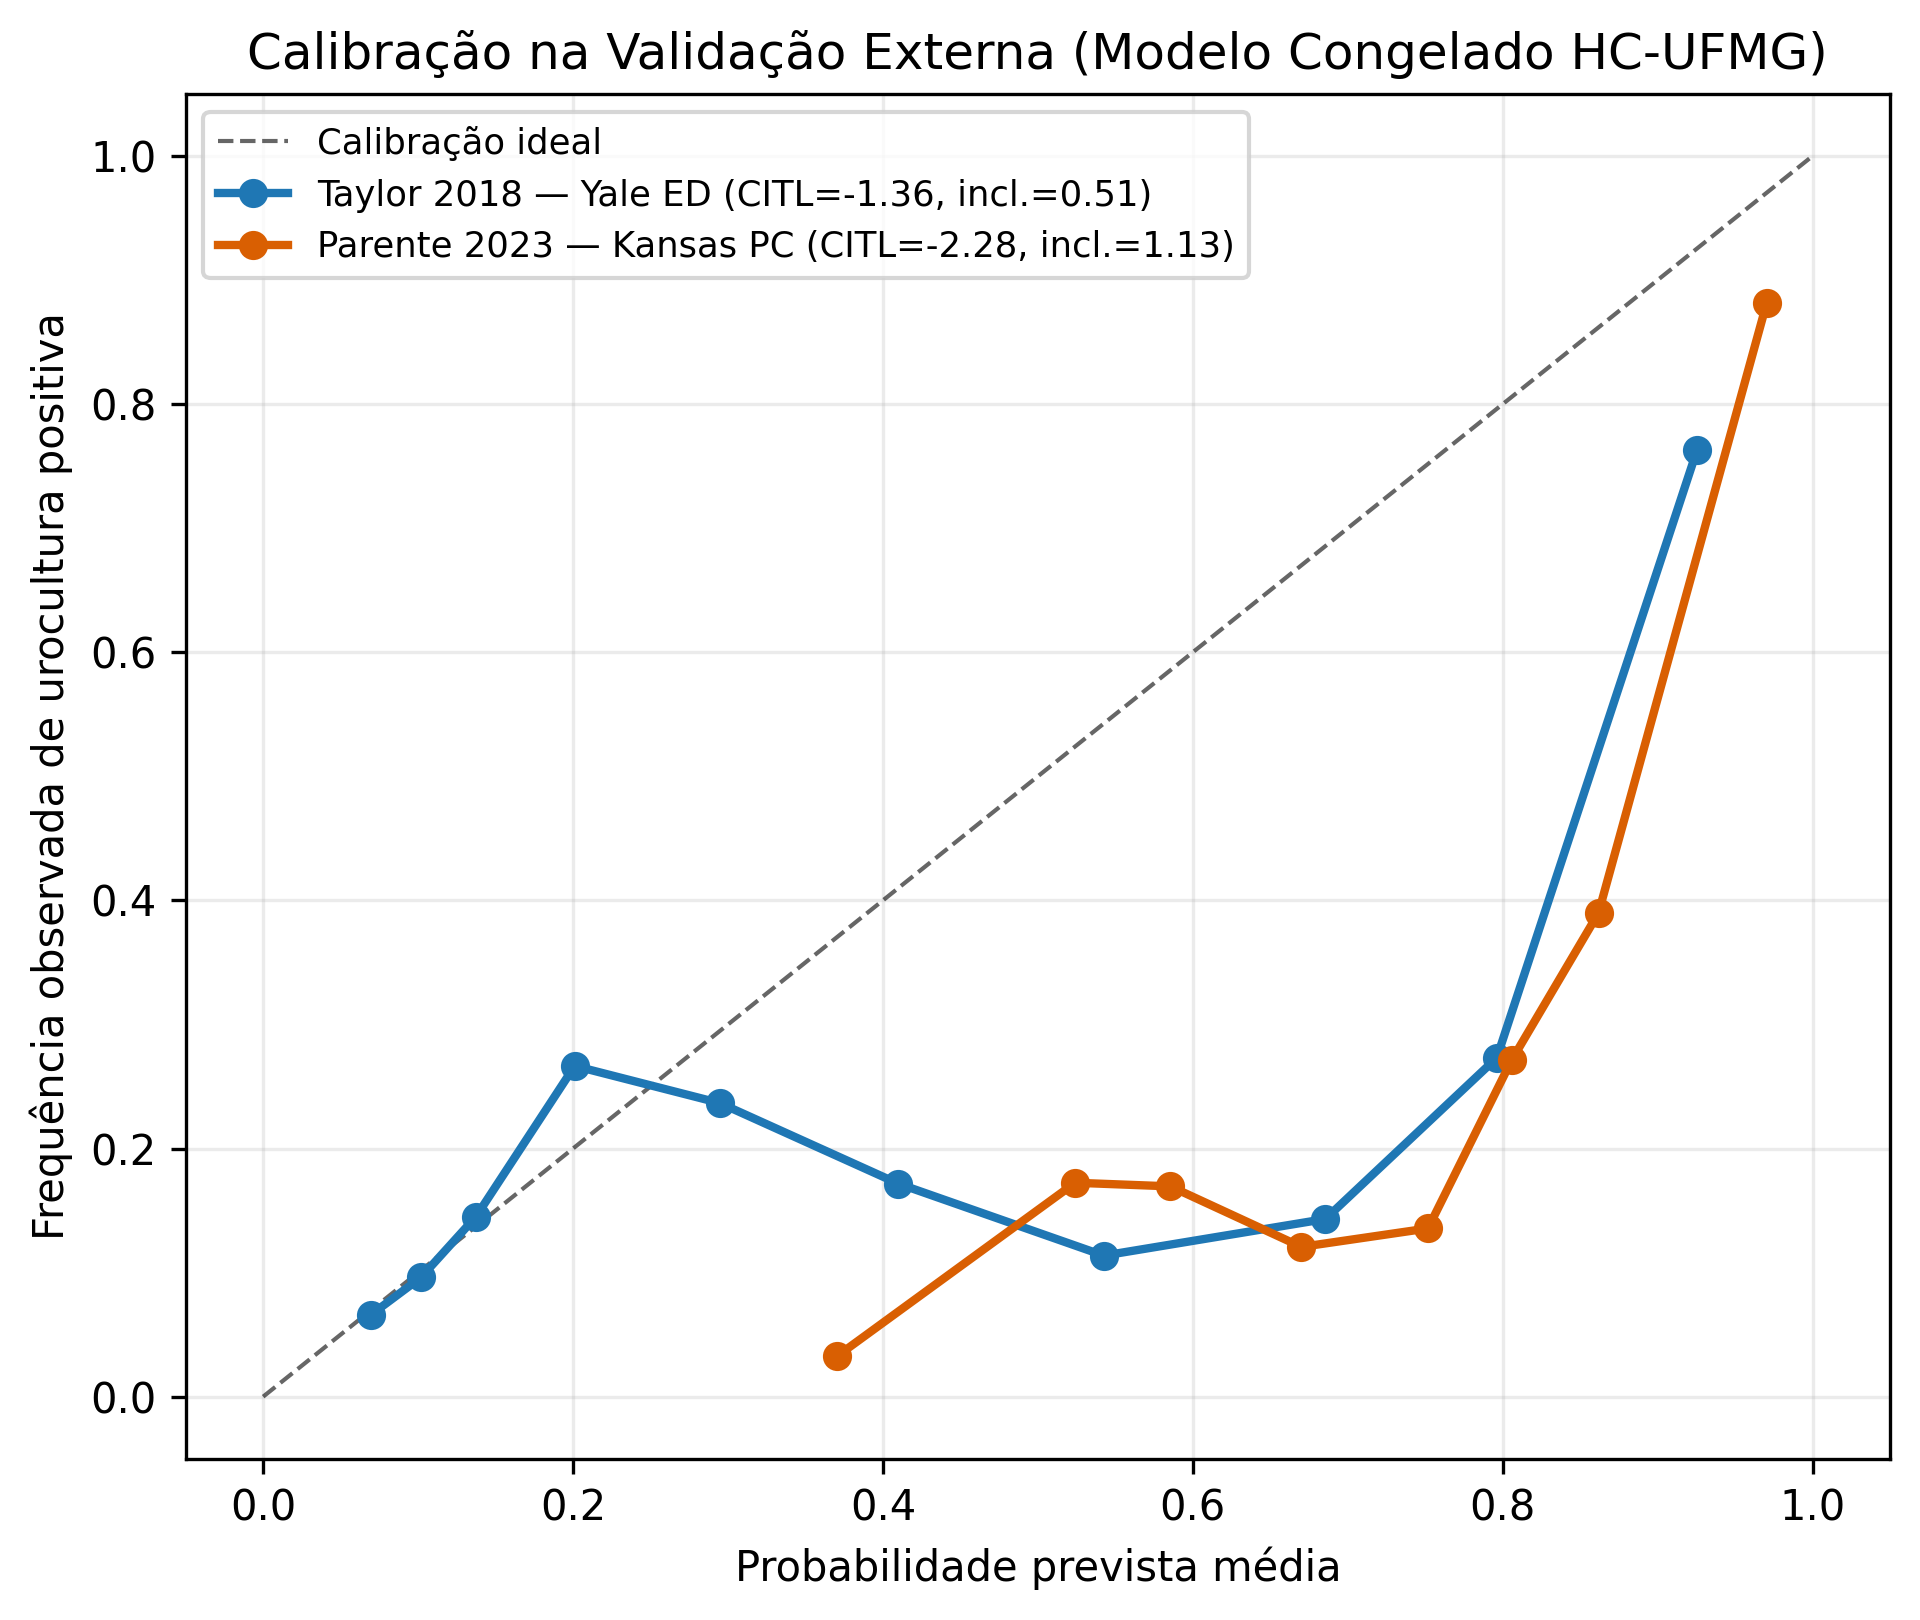


Arquivos salvos com sucesso em: /content/drive/MyDrive/Todos os arquivos GPT/resultados_validacao_externa_v6


In [ ]:
# Célula 2 — Validação Externa Completa (Taylor 2018 + Parente 2023) com PreviTU V6 congelado
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings("ignore")

BASE_DRIVE = Path("/content/drive/MyDrive/Todos os arquivos GPT")
ART_DIR = BASE_DRIVE / "previtu_v6_artefatos"
TAYLOR_PATH = BASE_DRIVE / "Taylor datasets" / "pone.0194085.s001.csv"
PARENTE_PATH = BASE_DRIVE / "Parente" / "PrimaryCare_Deidentified.txt"
OUT_DIR = BASE_DRIVE / "resultados_validacao_externa_v6"
OUT_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ART_DIR))
from previtu_core_v6 import PreviTU

modelo = PreviTU(via="sem_gram", regra_limiar="sensibilidade_95")
THR_HS95 = float(modelo.card["limiares"]["sensibilidade_95"])
THR_YOUDEN = float(modelo.card["limiares"]["youden"])
print(f"Modelo carregado: {modelo.versao} | SHA-256: {modelo.sha256[:12]}...")
print(f"Limiares congelados (HC-UFMG 2011–2022): sensibilidade_95={THR_HS95:.6f} | youden={THR_YOUDEN:.6f}")

# ---------------------------------------------------------------------------
# Funções de harmonização explícita e transparente (sem alterar o modelo)
# ---------------------------------------------------------------------------
NULL_TOKENS = {"", "NA", "NAN", "NULL", "NOT_REPORTED", "OTHER", "UNKNOWN", "MISSING", "<NA>"}

MAPA_FITA_EN = {
    "NEGATIVE": 0.0, "NEG": 0.0, "NONE": 0.0, "NORMAL": 0.0, "0": 0.0,
    "TRACE": 0.5, "TRACES": 0.5, "TR": 0.5, "0.5": 0.5,
    "SMALL": 1.0, "1+": 1.0, "+": 1.0, "1": 1.0, "LOW": 1.0, "FEW": 1.0, "LIGHT": 1.0, "POSITIVE": 1.0,
    "MODERATE": 2.0, "MOD": 2.0, "2+": 2.0, "++": 2.0, "2": 2.0,
    "LARGE": 3.0, "3+": 3.0, "+++": 3.0, "3": 3.0, "HIGH": 3.0, "MANY": 3.0, "MARKED": 3.0,
    "4+": 4.0, "++++": 4.0, "4": 4.0,
}

MAPA_FLORA_EN = {
    "NONE": 0.0, "NEGATIVE": 0.0, "NEG": 0.0, "0": 0.0, "ABSENT": 0.0,
    "FEW": 1.0, "RARE": 1.0, "TRACE": 1.0, "OCCASIONAL": 1.0, "SMALL": 1.0, "1+": 1.0, "+": 1.0, "1": 1.0,
    "MODERATE": 2.0, "MOD": 2.0, "2+": 2.0, "++": 2.0, "2": 2.0,
    "MANY": 3.0, "MARKED": 3.0, "LARGE": 3.0, "3+": 3.0, "+++": 3.0, "3": 3.0,
    "4+": 4.0, "++++": 4.0, "4": 4.0, "TNTC": 4.0,
}

MAPA_SEDIMENTO_CAT = {
    "NONE": 0.0, "NEGATIVE": 0.0, "NEG": 0.0, "0": 0.0,
    "TRACE": 2.0, "RARE": 2.0, "FEW": 3.0, "SMALL": 5.0,
    "MODERATE": 20.0, "MOD": 20.0,
    "LARGE": 50.0, "MANY": 50.0, "MARKED": 50.0,
    "TNTC": 100.0, "PACKED": 100.0,
}

def parse_fita(serie, mapa):
    out = np.full(len(serie), np.nan, dtype=float)
    for i, val in enumerate(serie):
        if pd.isna(val):
            continue
        s = str(val).strip().upper()
        if s in NULL_TOKENS:
            continue
        if s in mapa:
            out[i] = mapa[s]
            continue
        try:
            out[i] = float(s.replace(",", "."))
        except ValueError:
            pass
    return out

def parse_sedimento_en(serie):
    out = np.full(len(serie), np.nan, dtype=float)
    for i, val in enumerate(serie):
        if pd.isna(val):
            continue
        s = str(val).strip().upper()
        if s in NULL_TOKENS:
            continue
        if s in MAPA_SEDIMENTO_CAT:
            out[i] = MAPA_SEDIMENTO_CAT[s]
            continue
        if "TNTC" in s or "INCOUNT" in s or "PACKED" in s:
            out[i] = 100.0
            continue
        # Intervalo tipo "10-20" ou "5-10" -> ponto médio
        m_rng = re.search(r"(\d+(?:\.\d+)?)\s*[-–]\s*(\d+(?:\.\d+)?)", s)
        if m_rng:
            out[i] = (float(m_rng.group(1)) + float(m_rng.group(2))) / 2.0
            continue
        # ">100" ou ">=50"
        m_gt = re.search(r">=?\s*(\d+(?:\.\d+)?)", s)
        if m_gt:
            out[i] = min(float(m_gt.group(1)), 100.0)
            continue
        m_num = re.search(r"(\d+(?:\.\d+)?)", s)
        if m_num:
            out[i] = float(m_num.group(1))
    return out

def parse_densidade_en(serie):
    out = np.full(len(serie), np.nan, dtype=float)
    for i, val in enumerate(serie):
        if pd.isna(val):
            continue
        s = str(val).strip().upper().replace(",", ".")
        if s in NULL_TOKENS:
            continue
        m = re.search(r"(\d+(?:\.\d+)?)", s)
        if not m:
            continue
        num = float(m.group(1))
        if 1000.0 <= num <= 1060.0:
            num /= 1000.0
        if 1.000 <= num <= 1.060:
            out[i] = num
    return out

def parse_nitrito_en(serie):
    out = []
    for val in serie:
        if pd.isna(val):
            out.append(np.nan)
            continue
        s = str(val).strip().upper()
        if s in ("NEGATIVE", "NEG", "0"):
            out.append("Negativo")
        elif s in ("POSITIVE", "POS", "1", "SMALL", "MODERATE", "LARGE"):
            out.append("Positivo")
        else:
            out.append(np.nan)
    return np.array(out, dtype=object)

def parse_sexo_en(serie):
    out = []
    for val in serie:
        if pd.isna(val):
            out.append(np.nan)
            continue
        s = str(val).strip().upper()
        if s.startswith("F"):
            out.append("F")
        elif s.startswith("M"):
            out.append("M")
        else:
            out.append(np.nan)
    return np.array(out, dtype=object)

def parse_target(serie):
    s = serie.astype(str).str.strip().str.upper()
    return np.where(s.isin(["YES", "1", "TRUE", "POSITIVE", "POS"]), 1,
           np.where(s.isin(["NO", "0", "FALSE", "NEGATIVE", "NEG"]), 0, np.nan))

def harmonizar_para_v6(df_raw: pd.DataFrame, origem_codigo: str, nome_coorte: str):
    n = len(df_raw)
    h = pd.DataFrame(index=df_raw.index)
    h["Idade_anos"] = pd.to_numeric(df_raw["age"], errors="coerce") if "age" in df_raw.columns else np.nan
    h["Sexo"] = parse_sexo_en(df_raw["gender"]) if "gender" in df_raw.columns else np.nan
    h["Origem"] = origem_codigo

    h["UROT__PH"] = pd.to_numeric(df_raw["ua_ph"], errors="coerce") if "ua_ph" in df_raw.columns else np.nan
    h["UROT__GRAVID"] = parse_densidade_en(df_raw["ua_spec_grav"]) if "ua_spec_grav" in df_raw.columns else np.nan
    h["UROT__GRAVID_DESVIO_QUAD"] = (h["UROT__GRAVID"] - 1.015) ** 2

    h["UROT__ESTERASE"] = parse_fita(df_raw["ua_leuk"], MAPA_FITA_EN) if "ua_leuk" in df_raw.columns else np.nan
    h["UROT__NITRIT"] = parse_nitrito_en(df_raw["ua_nitrite"]) if "ua_nitrite" in df_raw.columns else np.nan
    h["UROT__HEMOGL"] = parse_fita(df_raw["ua_blood"], MAPA_FITA_EN) if "ua_blood" in df_raw.columns else np.nan
    h["UROT__GLIC"] = parse_fita(df_raw["ua_glucose"], MAPA_FITA_EN) if "ua_glucose" in df_raw.columns else np.nan
    h["UROT__SEDLEU"] = parse_sedimento_en(df_raw["ua_wbc"]) if "ua_wbc" in df_raw.columns else np.nan
    h["UROT__SEDHEM"] = parse_sedimento_en(df_raw["ua_rbc"]) if "ua_rbc" in df_raw.columns else np.nan
    h["UROT__FLORA"] = parse_fita(df_raw["ua_bacteria"], MAPA_FLORA_EN) if "ua_bacteria" in df_raw.columns else np.nan

    # Auditoria de ausentes
    aud = []
    for col in modelo.numericas + modelo.categoricas:
        if col == "UROT__GRAVID_DESVIO_QUAD":
            continue
        pct_na = float(h[col].isna().mean() * 100)
        exemplos = pd.Series(h[col].dropna()).unique()[:6].tolist()
        aud.append({
            "coorte": nome_coorte,
            "variavel_v6": col,
            "pct_ausente": round(pct_na, 2),
            "exemplos_harmonizados": str(exemplos),
        })
    return h, pd.DataFrame(aud)

def calibracao_logistica(y, p):
    p_clip = np.clip(p, 1e-6, 1 - 1e-6)
    lp = logit(p_clip).reshape(-1, 1)
    # Inclinação + intercepto
    lr = LogisticRegression(C=1e9, solver="lbfgs")
    lr.fit(lp, y)
    slope = float(lr.coef_[0, 0])
    # Calibração-in-the-large (intercepto com inclinação fixa = 1)
    from scipy.optimize import minimize_scalar
    res = minimize_scalar(lambda a: -np.mean(y * np.log(np.clip(expit(a + lp[:, 0]), 1e-12, 1)) +
                                             (1 - y) * np.log(np.clip(1 - expit(a + lp[:, 0]), 1e-12, 1))),
                          bounds=(-10, 10), method="bounded")
    citl = float(res.x)
    return citl, slope

def bootstrap_ci(y, p, groups=None, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    aucs, praucs = [], []
    if groups is not None:
        uniq = np.unique(groups)
        idx_by_g = pd.Series(np.arange(len(y))).groupby(groups).indices
        for _ in range(n_boot):
            sampled_g = rng.choice(uniq, size=len(uniq), replace=True)
            idx = np.concatenate([idx_by_g[g] for g in sampled_g])
            if len(np.unique(y[idx])) < 2:
                continue
            aucs.append(roc_auc_score(y[idx], p[idx]))
            praucs.append(average_precision_score(y[idx], p[idx]))
    else:
        n = len(y)
        for _ in range(n_boot):
            idx = rng.integers(0, n, size=n)
            if len(np.unique(y[idx])) < 2:
                continue
            aucs.append(roc_auc_score(y[idx], p[idx]))
            praucs.append(average_precision_score(y[idx], p[idx]))
    return (
        float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5)),
        float(np.percentile(praucs, 2.5)), float(np.percentile(praucs, 97.5)),
    )

def avaliar_coorte(nome, X_v6, y, groups=None, n_boot=500):
    valid = ~np.isnan(y)
    X_v6 = X_v6.loc[valid].reset_index(drop=True)
    y = y[valid].astype(int)
    g = groups[valid] if groups is not None else None

    p = modelo.prever_lote(X_v6)
    auroc = float(roc_auc_score(y, p))
    prauc = float(average_precision_score(y, p))
    brier = float(brier_score_loss(y, p))
    citl, slope = calibracao_logistica(y, p)
    auc_lo, auc_hi, pr_lo, pr_hi = bootstrap_ci(y, p, groups=g, n_boot=n_boot)

    # Limiar congelado sensibilidade 95%
    pred95 = (p >= THR_HS95).astype(int)
    tp = int(((pred95 == 1) & (y == 1)).sum())
    fn = int(((pred95 == 0) & (y == 1)).sum())
    tn = int(((pred95 == 0) & (y == 0)).sum())
    fp = int(((pred95 == 1) & (y == 0)).sum())
    sens95 = tp / (tp + fn) if (tp + fn) else np.nan
    spec95 = tn / (tn + fp) if (tn + fp) else np.nan
    npv95 = tn / (tn + fn) if (tn + fn) else np.nan
    ppv95 = tp / (tp + fp) if (tp + fp) else np.nan
    abaixo_pct = float(np.mean(p < THR_HS95) * 100)
    fn_mil = fn / len(y) * 1000.0

    # Limiar congelado Youden
    predY = (p >= THR_YOUDEN).astype(int)
    tpY = int(((predY == 1) & (y == 1)).sum())
    fnY = int(((predY == 0) & (y == 1)).sum())
    tnY = int(((predY == 0) & (y == 0)).sum())
    fpY = int(((predY == 1) & (y == 0)).sum())

    res = {
        "coorte": nome,
        "n_exames": int(len(y)),
        "n_positivas": int(y.sum()),
        "prevalencia_pct": round(float(y.mean() * 100), 2),
        "auroc": round(auroc, 4),
        "auroc_ic95_inf": round(auc_lo, 4),
        "auroc_ic95_sup": round(auc_hi, 4),
        "pr_auc": round(prauc, 4),
        "pr_auc_ic95_inf": round(pr_lo, 4),
        "pr_auc_ic95_sup": round(pr_hi, 4),
        "brier": round(brier, 4),
        "cal_intercepto_citl": round(citl, 4),
        "cal_inclinacao": round(slope, 4),
        "hs95_sens": round(sens95, 4),
        "hs95_spec": round(spec95, 4),
        "hs95_vpn": round(npv95, 4),
        "hs95_vpp": round(ppv95, 4),
        "hs95_abaixo_limiar_pct": round(abaixo_pct, 2),
        "hs95_fn_por_1000": round(fn_mil, 2),
        "youden_sens": round(tpY / (tpY + fnY), 4) if (tpY + fnY) else np.nan,
        "youden_spec": round(tnY / (tnY + fpY), 4) if (tnY + fpY) else np.nan,
    }
    return res, y, p

# ---------------------------------------------------------------------------
# 1. Carregar e avaliar Taylor et al. (2018) — Yale ED
# ---------------------------------------------------------------------------
print("\n--- Carregando Taylor et al. (2018) — Yale ED ---")
cols_taylor = ["PATID", "split", "UCX_abnormal", "age", "gender", "ua_ph", "ua_spec_grav",
               "ua_leuk", "ua_nitrite", "ua_blood", "ua_glucose", "ua_wbc", "ua_rbc", "ua_bacteria"]
hdr_taylor = pd.read_csv(TAYLOR_PATH, nrows=0).columns.tolist()
use_taylor = [c for c in cols_taylor if c in hdr_taylor]
df_taylor = pd.read_csv(TAYLOR_PATH, usecols=use_taylor, low_memory=False)
print(f"Taylor carregado: {df_taylor.shape} | Colunas lidas: {use_taylor}")

for col in ["ua_leuk", "ua_nitrite", "ua_blood", "ua_glucose", "ua_wbc", "ua_rbc", "ua_bacteria"]:
    if col in df_taylor.columns:
        print(f"  [Taylor bruto] {col}: {df_taylor[col].value_counts(dropna=False).head(8).to_dict()}")

X_taylor, aud_taylor = harmonizar_para_v6(df_taylor, origem_codigo="PA", nome_coorte="Taylor_2018_Yale_ED")
y_taylor = parse_target(df_taylor["UCX_abnormal"])
g_taylor = df_taylor["PATID"].astype(str).to_numpy() if "PATID" in df_taylor.columns else None

res_taylor_all, yt_all, pt_all = avaliar_coorte(
    "Taylor 2018 — Yale ED (coorte total)", X_taylor, y_taylor, groups=g_taylor, n_boot=300
)

# Subconjunto de validação oficial do artigo (split == 'validation')
resultados = [res_taylor_all]
if "split" in df_taylor.columns:
    mask_val = df_taylor["split"].astype(str).str.lower().str.contains("val")
    if mask_val.sum() > 0:
        res_taylor_val, _, _ = avaliar_coorte(
            "Taylor 2018 — Yale ED (split validation)",
            X_taylor.loc[mask_val].reset_index(drop=True),
            y_taylor[mask_val],
            groups=g_taylor[mask_val] if g_taylor is not None else None,
            n_boot=300,
        )
        resultados.append(res_taylor_val)

# ---------------------------------------------------------------------------
# 2. Carregar e avaliar Parente et al. (2023) — University of Kansas Primary Care
# ---------------------------------------------------------------------------
print("\n--- Carregando Parente et al. (2023) — Primary Care ---")
df_parente = pd.read_csv(PARENTE_PATH, sep="\t", low_memory=False)
print(f"Parente carregado: {df_parente.shape}")

X_parente, aud_parente = harmonizar_para_v6(df_parente, origem_codigo="BC", nome_coorte="Parente_2023_Kansas_PC")
y_parente = parse_target(df_parente["UCX_abnormal"])

res_parente, yp, pp = avaliar_coorte(
    "Parente 2023 — Kansas Primary Care (>=10^5 UFC/mL)", X_parente, y_parente, groups=None, n_boot=1000
)
resultados.append(res_parente)

if "UCX_abnormal_alt" in df_parente.columns:
    y_parente_alt = parse_target(df_parente["UCX_abnormal_alt"])
    res_parente_alt, _, _ = avaliar_coorte(
        "Parente 2023 — Kansas Primary Care (>=10^4 UFC/mL, sens.)", X_parente, y_parente_alt, groups=None, n_boot=1000
    )
    resultados.append(res_parente_alt)

# ---------------------------------------------------------------------------
# 3. Exportar tabelas consolidadas + auditoria de harmonização
# ---------------------------------------------------------------------------
df_res = pd.DataFrame(resultados)
df_aud = pd.concat([aud_taylor, aud_parente], ignore_index=True)

df_res.to_csv(OUT_DIR / "summary_validacao_externa_v6.csv", index=False)
df_aud.to_csv(OUT_DIR / "auditoria_harmonizacao_colunas.csv", index=False)

with pd.ExcelWriter(OUT_DIR / "Resumo_Validacao_Externa_PreviTU_V6.xlsx", engine="openpyxl") as writer:
    df_res.to_excel(writer, sheet_name="Validacao_Externa", index=False)
    df_aud.to_excel(writer, sheet_name="Auditoria_Harmonizacao", index=False)

print("\n=== RESULTADOS CONSOLIDADOS DA VALIDAÇÃO EXTERNA (PREVITÙ V6 SEM GRAM) ===")
print(df_res[["coorte", "n_exames", "prevalencia_pct", "auroc", "auroc_ic95_inf", "auroc_ic95_sup",
              "pr_auc", "brier", "cal_intercepto_citl", "cal_inclinacao",
              "hs95_sens", "hs95_spec", "hs95_abaixo_limiar_pct", "hs95_fn_por_1000"]].to_string(index=False))

print("\n=== AUDITORIA DE VARIÁVEIS AUSENTES ===")
print(df_aud.to_string(index=False))

# ---------------------------------------------------------------------------
# 4. Figuras publicação (ROC + PR e Calibração)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), dpi=300)

for label, yy, pp_arr, color in [
    (f"Taylor 2018 — Yale ED (n={len(yt_all):,}; AUROC={res_taylor_all['auroc']:.3f})", yt_all, pt_all, "#1f77b4"),
    (f"Parente 2023 — Kansas PC (n={len(yp):,}; AUROC={res_parente['auroc']:.3f})", yp, pp, "#d95f02"),
]:
    fpr, tpr, _ = roc_curve(yy, pp_arr)
    axes[0].plot(fpr, tpr, lw=2, color=color, label=label)
    prec, rec, _ = precision_recall_curve(yy, pp_arr)
    ap = average_precision_score(yy, pp_arr)
    axes[1].plot(rec, prec, lw=2, color=color, label=f"{label.split(';')[0]}; PR-AUC={ap:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
axes[0].set_title("Curva ROC — Validação Externa Geográfica (PreviTU V6 sem Gram)")
axes[0].set_xlabel("1 − Especificidade (Taxa de Falsos Positivos)")
axes[0].set_ylabel("Sensibilidade")
axes[0].legend(loc="lower right", fontsize=8.5)
axes[0].grid(alpha=0.25)

axes[1].set_title("Curva Precisão–Revocação — Validação Externa Geográfica")
axes[1].set_xlabel("Sensibilidade (Revocação)")
axes[1].set_ylabel("Valor Preditivo Positivo (Precisão)")
axes[1].legend(loc="lower left", fontsize=8.5)
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_validacao_externa_roc_pr.png", dpi=300)
plt.show()

# Curva de calibração em 10 decis
fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Calibração ideal")
for label, yy, pp_arr, color, bins in [
    (f"Taylor 2018 — Yale ED (CITL={res_taylor_all['cal_intercepto_citl']:+.2f}, incl.={res_taylor_all['cal_inclinacao']:.2f})", yt_all, pt_all, "#1f77b4", 10),
    (f"Parente 2023 — Kansas PC (CITL={res_parente['cal_intercepto_citl']:+.2f}, incl.={res_parente['cal_inclinacao']:.2f})", yp, pp, "#d95f02", 8),
]:
    q = pd.qcut(pp_arr, q=bins, duplicates="drop")
    cal_df = pd.DataFrame({"y": yy, "p": pp_arr, "q": q}).groupby("q", observed=True).agg(
        p_mean=("p", "mean"), y_mean=("y", "mean")
    )
    ax.plot(cal_df["p_mean"], cal_df["y_mean"], "o-", lw=2, color=color, label=label)

ax.set_title("Calibração na Validação Externa (Modelo Congelado HC-UFMG)")
ax.set_xlabel("Probabilidade prevista média")
ax.set_ylabel("Frequência observada de urocultura positiva")
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_validacao_externa_calibracao.png", dpi=300)
plt.show()

print("\nArquivos salvos com sucesso em:", OUT_DIR)


In [ ]:
# Célula 3 — Diagnóstico de microscopia reflexa (Yale) + Recalibração local sem vazamento (TRIPOD+AI)
from scipy.optimize import minimize_scalar
from sklearn.model_selection import StratifiedKFold

def resumo_operacional(nome, y_true, p_pred, thr=THR_HS95):
    citl, slope = calibracao_logistica(y_true, p_pred)
    pred = (p_pred >= thr).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    return {
        "cenario": nome,
        "n": int(len(y_true)),
        "prev_pct": round(float(y_true.mean() * 100), 2),
        "auroc": round(float(roc_auc_score(y_true, p_pred)), 4),
        "pr_auc": round(float(average_precision_score(y_true, p_pred)), 4),
        "brier": round(float(brier_score_loss(y_true, p_pred)), 4),
        "citl": round(citl, 4),
        "inclinacao": round(slope, 4),
        "hs95_sens": round(tp / (tp + fn), 4) if (tp + fn) else np.nan,
        "hs95_spec": round(tn / (tn + fp), 4) if (tn + fp) else np.nan,
        "hs95_abaixo_pct": round(float(np.mean(p_pred < thr) * 100), 2),
        "hs95_fn_por_1000": round(fn / len(y_true) * 1000.0, 2),
    }

def ajustar_intercepto(y_fit, p_fit):
    lp = logit(np.clip(p_fit, 1e-6, 1 - 1e-6))
    res = minimize_scalar(
        lambda a: -np.mean(
            y_fit * np.log(np.clip(expit(a + lp), 1e-12, 1))
            + (1 - y_fit) * np.log(np.clip(1 - expit(a + lp), 1e-12, 1))
        ),
        bounds=(-10, 10),
        method="bounded",
    )
    return float(res.x)

linhas = []

# =========================================================================
# 1. Diagnóstico de microscopia reflexa em Taylor et al. (2018 — Yale ED)
# =========================================================================
valid_t = ~np.isnan(y_taylor)
Xt = X_taylor.loc[valid_t].reset_index(drop=True)
yt = y_taylor[valid_t].astype(int)
split_t = df_taylor.loc[valid_t, "split"].astype(str).str.lower().reset_index(drop=True)

tem_micro = Xt["UROT__SEDLEU"].notna() & Xt["UROT__FLORA"].notna()
print("=== DIAGNÓSTICO DE MICROSCOPIA REFLEXA (YALE ED) ===")
print(f"Com microscopia (SEDLEU + FLORA): n={tem_micro.sum():,} | prevalência={yt[tem_micro].mean()*100:.2f}%")
print(f"Sem microscopia (ausente):        n={(~tem_micro).sum():,} | prevalência={yt[~tem_micro].mean()*100:.2f}%")

# 1a. Modelo congelado apenas nos exames COM microscopia reportada
p_t_micro = modelo.prever_lote(Xt.loc[tem_micro].reset_index(drop=True))
linhas.append(resumo_operacional("Taylor 2018 — Apenas COM microscopia (congelado)", yt[tem_micro], p_t_micro))

# 1b. Análise de sensibilidade: quando microscopia ausente + esterase==0 + nitrito=='Negativo' -> 0.0 (fluxo reflexo)
Xt_reflex = Xt.copy()
fita_neg = (Xt_reflex["UROT__ESTERASE"] == 0.0) & (Xt_reflex["UROT__NITRIT"] == "Negativo")
for col_m in ("UROT__SEDLEU", "UROT__SEDHEM", "UROT__FLORA"):
    mask_fill = Xt_reflex[col_m].isna() & fita_neg
    Xt_reflex.loc[mask_fill, col_m] = 0.0
p_t_reflex = modelo.prever_lote(Xt_reflex)
linhas.append(resumo_operacional("Taylor 2018 — Fluxo reflexo harmonizado (fita neg -> micro 0)", yt, p_t_reflex))

# =========================================================================
# 2. Recalibração local SEM vazamento (TRIPOD+AI)
# =========================================================================
# 2a. Taylor 2018: ajusta recalibração no split 'training' e avalia no split 'validation'
m_tr = split_t.str.contains("train")
m_va = split_t.str.contains("val")
p_tr_raw = modelo.prever_lote(Xt.loc[m_tr].reset_index(drop=True))
p_va_raw = modelo.prever_lote(Xt.loc[m_va].reset_index(drop=True))
y_tr, y_va = yt[m_tr], yt[m_va]

# Intercepto apenas (update-in-the-large)
a_t = ajustar_intercepto(y_tr, p_tr_raw)
p_va_int = expit(a_t + logit(np.clip(p_va_raw, 1e-6, 1 - 1e-6)))
linhas.append(resumo_operacional("Taylor 2018 (val) — Recalibrado (só intercepto)", y_va, p_va_int))

# Intercepto + inclinação (recalibração logística)
lr_t = LogisticRegression(C=1e9, solver="lbfgs")
lr_t.fit(logit(np.clip(p_tr_raw, 1e-6, 1 - 1e-6)).reshape(-1, 1), y_tr)
p_va_log = lr_t.predict_proba(logit(np.clip(p_va_raw, 1e-6, 1 - 1e-6)).reshape(-1, 1))[:, 1]
linhas.append(resumo_operacional("Taylor 2018 (val) — Recalibrado (intercepto + inclinação)", y_va, p_va_log))

# Recalibração logística também no cenário de fluxo reflexo (val)
p_tr_ref = p_t_reflex[m_tr]
p_va_ref = p_t_reflex[m_va]
lr_ref = LogisticRegression(C=1e9, solver="lbfgs")
lr_ref.fit(logit(np.clip(p_tr_ref, 1e-6, 1 - 1e-6)).reshape(-1, 1), y_tr)
p_va_ref_log = lr_ref.predict_proba(logit(np.clip(p_va_ref, 1e-6, 1 - 1e-6)).reshape(-1, 1))[:, 1]
linhas.append(resumo_operacional("Taylor 2018 (val) — Reflexo + Recalibração logística", y_va, p_va_ref_log))

# 2b. Parente 2023 (n=472): recalibração out-of-fold (5-fold estratificada, sem vazamento)
valid_p = ~np.isnan(y_parente)
Xp = X_parente.loc[valid_p].reset_index(drop=True)
yp_bin = y_parente[valid_p].astype(int)
p_p_raw = modelo.prever_lote(Xp)
lp_p = logit(np.clip(p_p_raw, 1e-6, 1 - 1e-6))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_p_int_oof = np.zeros_like(p_p_raw)
p_p_log_oof = np.zeros_like(p_p_raw)
for tr_idx, va_idx in skf.split(Xp, yp_bin):
    a_k = ajustar_intercepto(yp_bin[tr_idx], p_p_raw[tr_idx])
    p_p_int_oof[va_idx] = expit(a_k + lp_p[va_idx])
    lr_k = LogisticRegression(C=1e9, solver="lbfgs")
    lr_k.fit(lp_p[tr_idx].reshape(-1, 1), yp_bin[tr_idx])
    p_p_log_oof[va_idx] = lr_k.predict_proba(lp_p[va_idx].reshape(-1, 1))[:, 1]

linhas.append(resumo_operacional("Parente 2023 (5-fold OOF) — Recalibrado (só intercepto)", yp_bin, p_p_int_oof))
linhas.append(resumo_operacional("Parente 2023 (5-fold OOF) — Recalibrado (intercepto + inclinação)", yp_bin, p_p_log_oof))

df_extra = pd.DataFrame(linhas)
df_extra.to_csv(OUT_DIR / "analise_sensibilidade_recalibracao_externa.csv", index=False)
print("\n=== ANÁLISE COMPLEMENTAR: FLUXO REFLEXO E RECALIBRAÇÃO LOCAL ===")
print(df_extra.to_string(index=False))

=== DIAGNÓSTICO DE MICROSCOPIA REFLEXA (YALE ED) ===
Com microscopia (SEDLEU + FLORA): n=49,308 | prevalência=31.40%
Sem microscopia (ausente):        n=31,079 | prevalência=9.01%

=== ANÁLISE COMPLEMENTAR: FLUXO REFLEXO E RECALIBRAÇÃO LOCAL ===
                                                          cenario     n  prev_pct  auroc  pr_auc  brier    citl  inclinacao  hs95_sens  hs95_spec  hs95_abaixo_pct  hs95_fn_por_1000
                 Taylor 2018 — Apenas COM microscopia (congelado) 49308     31.40 0.8232  0.7110 0.1573 -0.0855      0.7219     0.9977     0.0277             1.97              0.71
    Taylor 2018 — Fluxo reflexo harmonizado (fita neg -> micro 0) 80387     22.74 0.8367  0.6467 0.1338 -0.3817      0.7046     0.9780     0.1679            13.47              5.00
                  Taylor 2018 (val) — Recalibrado (só intercepto) 16077     22.18 0.6975  0.5290 0.1563 -0.0490      0.4984     0.8360     0.3701            32.44             36.39
        Taylor 2018 (val) — Re